# HOG and Linear SVM

Gradient orientations describe the strokes of a digit. A linear margin classifier then works on those local histograms.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Stroke descriptors

Upsampling provides room for spatial cells. It adds no new source pixels.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import zoom
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from gallery.vision import digits_split, class_scores, confusion


def descriptor(image, visualise=False):
    return hog(
        zoom(image, 3, order=1),
        orientations=9,
        pixels_per_cell=(6, 6),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=visualise,
    )

## Classify held-out digits

The scaler and classifier are fitted on the training descriptors.

Accuracy 0.971 | Balanced accuracy 0.971 | MCC 0.968
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.979     1.000     0.989        46
           2      1.000     0.977     0.989        44
           3      1.000     0.935     0.966        46
           4      0.978     1.000     0.989        45
           5      1.000     0.978     0.989        46
           6      1.000     0.978     0.989        45
           7      0.956     0.956     0.956        45
           8      0.889     0.930     0.909        43
           9      0.915     0.956     0.935        45

    accuracy                          0.971       450
   macro avg      0.972     0.971     0.971       450
weighted avg      0.972     0.971     0.971       450



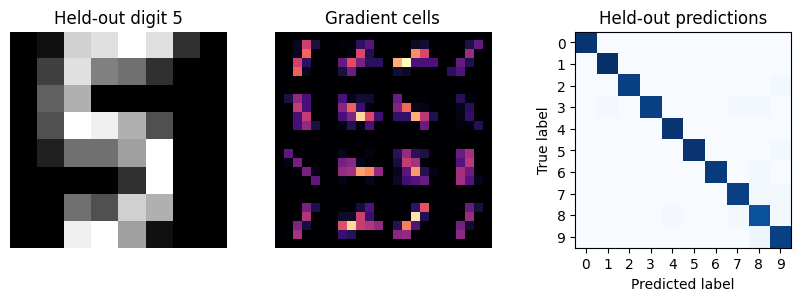

In [3]:
train, test, y, y_test = digits_split()
model = make_pipeline(StandardScaler(), LinearSVC(C=0.05, random_state=17, max_iter=6000))
model.fit(np.stack([descriptor(x) for x in train]), y)
pred = model.predict(np.stack([descriptor(x) for x in test]))
class_scores(y_test, pred)
fig, axes = plt.subplots(1, 3, figsize=(8.3, 2.9), constrained_layout=True)
axes[0].imshow(test[0], cmap="gray")
axes[0].set_title(f"Held-out digit {y_test[0]}")
axes[1].imshow(descriptor(test[0], True)[1], cmap="magma")
axes[1].set_title("Gradient cells")
for ax in axes[:2]:
    ax.axis("off")
confusion(axes[2], y_test, pred)
plt.show()

## Reading the result

A confusion between similarly shaped digits can persist even when the stroke representation is consistent. The reference and predicted labels are both available for inspection.

## References

[Dalal and Triggs, Histograms of Oriented Gradients (2005)](https://doi.org/10.1109/CVPR.2005.177)

[scikit-learn, LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Image and video generators and evaluation](../../../gallery/vision.py)